# Notebook 5: Practical Applications of Token Probabilities

## What Can We Do With Token Probabilities?

Now that we understand how LLMs produce token probabilities, let's explore practical applications:

1. **Perplexity** — Measuring how "surprised" a model is by text
2. **Confidence heatmaps** — Visualizing per-token confidence in generated text
3. **Uncertainty detection** — Spotting where the model is guessing
4. **Comparing completions** — Ranking alternative outputs by probability

We'll continue using GPT-2 for full logit access. These techniques apply identically to larger models — the math is the same, the distributions are just sharper.

In [1]:
import torch
import torch.nn.functional as F
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")
model.eval()

def score_text(text):
    """Score each token in a text: what probability did the model assign to each actual token?"""
    input_ids = tokenizer.encode(text, return_tensors="pt")
    
    with torch.no_grad():
        logits = model(input_ids).logits
    
    # logits[0, i] predicts token at position i+1
    shift_logits = logits[0, :-1, :]
    shift_labels = input_ids[0, 1:]
    
    all_probs = F.softmax(shift_logits, dim=-1)
    token_probs = all_probs.gather(1, shift_labels.unsqueeze(1)).squeeze(1)
    token_logprobs = torch.log(token_probs)
    
    # Also get top alternatives at each position
    results = []
    for i in range(len(shift_labels)):
        top5_probs, top5_ids = torch.topk(all_probs[i], 5)
        alternatives = [(tokenizer.decode([tid]), p.item()) for tid, p in zip(top5_ids, top5_probs)]
        
        results.append({
            "position": i + 1,
            "token": tokenizer.decode([shift_labels[i]]),
            "token_id": shift_labels[i].item(),
            "prob": token_probs[i].item(),
            "logprob": token_logprobs[i].item(),
            "alternatives": alternatives,
        })
    
    return results

print("Utility functions loaded ✓")

/Users/nijjohnson/Projects/token-probabilities/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 24671.40it/s]

Utility functions loaded ✓


## Application 1: Perplexity — How Surprised Is the Model?

**Perplexity** is the standard metric for evaluating language models. It measures how well the model predicts text:

$$\text{PPL} = \exp\left(-\frac{1}{N}\sum_{i=1}^{N} \log P(t_i | t_1, \ldots, t_{i-1})\right)$$

**Interpretation:** If a model has perplexity 10 on some text, it's as uncertain as if it were choosing uniformly among 10 options at each step.

- **Low perplexity (1-50):** Text is very predictable to the model
- **High perplexity (100+):** Text is surprising/unusual
- **Perplexity of 1:** Model predicted every token with 100% confidence

=== Perplexity Comparison ===

  Natural English            PPL =     20.8
  Wikipedia-style            PPL =     25.1
  Technical                  PPL =    414.4
  Simple repetition          PPL =      6.9
  Unusual but valid          PPL =   1006.0
  Nonsense                   PPL =   1593.0
  Random tokens              PPL =   2448.8


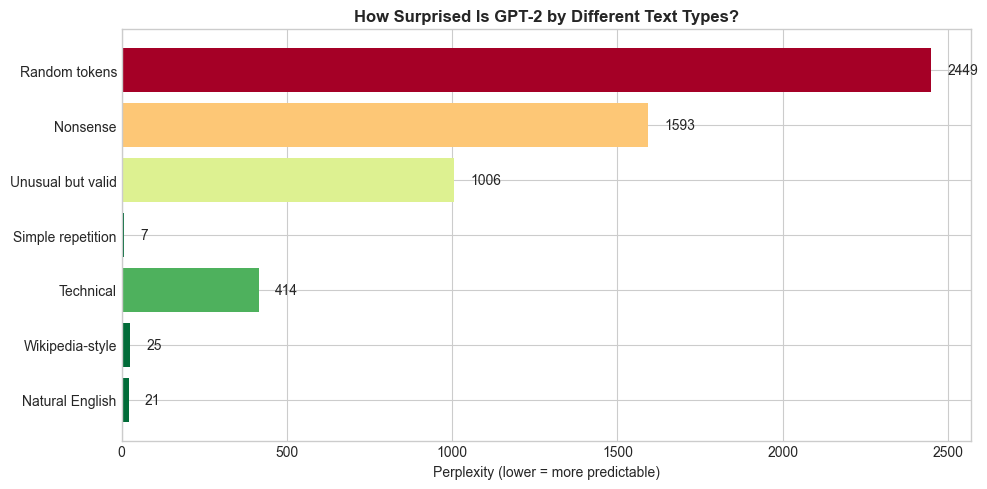

In [2]:
def compute_perplexity(text):
    """Compute perplexity of a text."""
    results = score_text(text)
    logprobs = [r["logprob"] for r in results]
    avg_logprob = np.mean(logprobs)
    return np.exp(-avg_logprob), results

# Compare perplexity across different text types
texts = {
    "Natural English":    "The weather today is sunny and warm with a gentle breeze blowing from the west.",
    "Wikipedia-style":    "The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in Paris.",
    "Technical":          "The transformer uses multi-head self-attention to model dependencies regardless of distance.",
    "Simple repetition":  "I like cats. I like dogs. I like birds. I like fish. I like animals.",
    "Unusual but valid":  "The melancholy saxophone wept through corridors of abandoned mathematics.",
    "Nonsense":           "Colorless green ideas sleep furiously beside the quantum teapot rebellion.",
    "Random tokens":      "Klarg bznorp fweem quizzle blat moonshard twerp axiom pickle.",
}

print("=== Perplexity Comparison ===\n")
ppl_results = {}
for label, text in texts.items():
    ppl, _ = compute_perplexity(text)
    ppl_results[label] = ppl
    print(f"  {label:25s}  PPL = {ppl:8.1f}")

# Visualize
fig, ax = plt.subplots(figsize=(10, 5))
labels = list(ppl_results.keys())
ppls = list(ppl_results.values())
max_ppl = max(ppls)

colors = plt.cm.RdYlGn_r(np.array(ppls) / max_ppl)
bars = ax.barh(labels, ppls, color=colors)
ax.set_xlabel("Perplexity (lower = more predictable)")
ax.set_title("How Surprised Is GPT-2 by Different Text Types?", fontweight="bold")

for bar, ppl in zip(bars, ppls):
    ax.text(bar.get_width() + max_ppl * 0.02, bar.get_y() + bar.get_height() / 2,
            f"{ppl:.0f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

## Application 2: Confidence Heatmap

Visualize the model's confidence for each token in a text. Green = confident, red = uncertain. This immediately reveals which parts of a text the model finds predictable vs. surprising.

--- Natural, predictable text ---


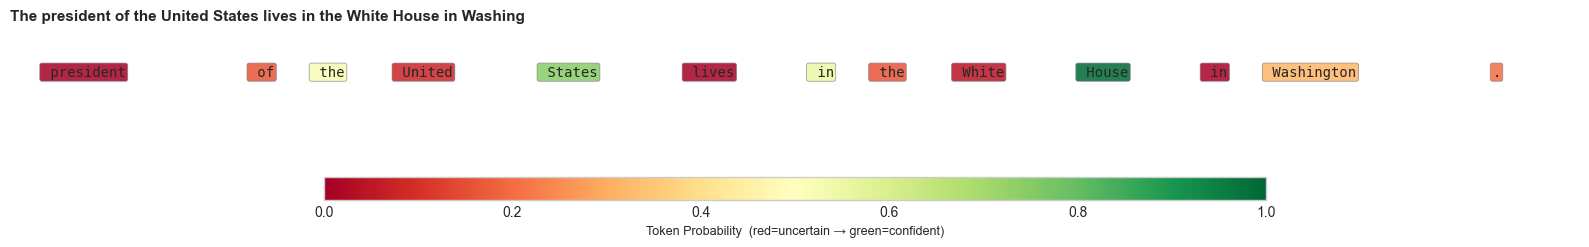


--- Same structure, surprising content ---


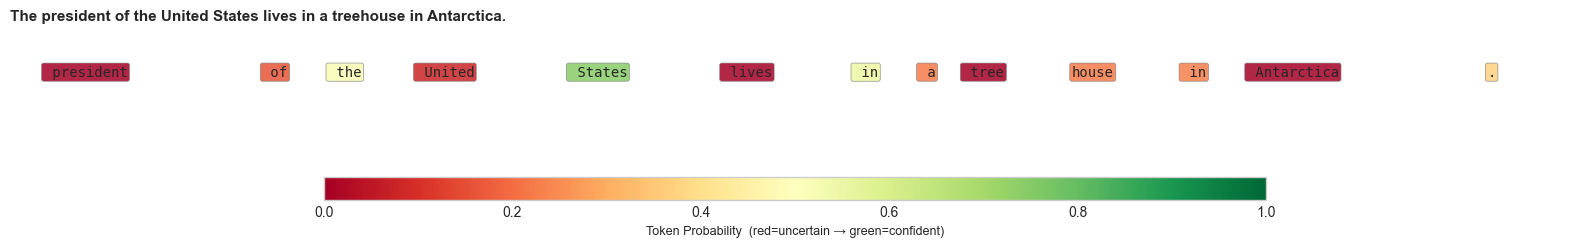

In [3]:
def confidence_heatmap(text, title=None):
    """Display a token-level confidence heatmap for a text."""
    results = score_text(text)
    
    tokens = [r["token"] for r in results]
    probs = [r["prob"] for r in results]
    
    fig, ax = plt.subplots(figsize=(16, 2.5))
    
    # Lay out tokens with colored backgrounds
    x_pos = 0
    for token, prob in zip(tokens, probs):
        color = plt.cm.RdYlGn(prob)
        token_display = token.replace("\n", "↵")
        
        ax.text(x_pos, 0.5, token_display, fontsize=10, fontfamily="monospace",
                ha="left", va="center",
                bbox=dict(boxstyle="round,pad=0.15", facecolor=color, alpha=0.85, edgecolor="gray", linewidth=0.5))
        x_pos += max(len(token_display) * 0.13, 0.25)
    
    ax.set_xlim(-0.2, x_pos + 0.3)
    ax.set_ylim(0, 1)
    ax.axis("off")
    
    display_title = title or text[:70]
    ax.set_title(display_title, fontsize=11, fontweight="bold", loc="left")
    
    # Colorbar
    sm = plt.cm.ScalarMappable(cmap=plt.cm.RdYlGn, norm=plt.Normalize(0, 1))
    cbar = plt.colorbar(sm, ax=ax, orientation="horizontal", pad=0.35, aspect=40, shrink=0.6)
    cbar.set_label("Token Probability  (red=uncertain → green=confident)", fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    return results

# Predictable text
print("--- Natural, predictable text ---")
_ = confidence_heatmap("The president of the United States lives in the White House in Washington.")

# Unusual combinations
print("\n--- Same structure, surprising content ---")
_ = confidence_heatmap("The president of the United States lives in a treehouse in Antarctica.")

## Application 3: Uncertainty Detection — Spotting Low-Confidence Tokens

When a model generates text with low token probabilities, it may be "guessing." We can flag these tokens as potentially unreliable — a simple hallucination detector.

In [4]:
def detect_uncertainty(text, threshold=0.05):
    """Flag tokens where the model assigns low probability — potential hallucination signals."""
    results = score_text(text)
    
    print(f'Text: "{text}"\n')
    
    # Display all tokens with uncertainty flags
    print(f"{'Pos':>3s}  {'Token':>15s}  {'Prob':>8s}  {'Flag':>6s}  What the model preferred")
    print("-" * 75)
    
    flagged = []
    for r in results:
        flag = " ⚠️" if r["prob"] < threshold else ""
        
        # Show what the model actually preferred
        top_alt = r["alternatives"][0]
        preferred = f'"{ top_alt[0].strip()}" ({top_alt[1]:.1%})' if top_alt[0].strip() != r["token"].strip() else "—"
        
        print(f"{r['position']:3d}  {r['token']:>15s}  {r['prob']:8.4f}  {flag:>6s}  {preferred}")
        
        if r["prob"] < threshold:
            flagged.append(r)
    
    print(f"\n{len(flagged)} / {len(results)} tokens flagged as low-confidence (< {threshold:.0%})")
    
    if flagged:
        print("\nLow-confidence tokens and their alternatives:")
        for r in flagged:
            alts = ", ".join([f'"{ tok.strip()}" ({p:.1%})' for tok, p in r["alternatives"][:3]])
            print(f'  "{r["token"].strip()}" (P={r["prob"]:.4f}) → model preferred: {alts}')
    
    return results, flagged

# True statement — should have fewer flags
print("=" * 75)
print("TRUE STATEMENT")
print("=" * 75)
_, flagged1 = detect_uncertainty(
    "Paris is the capital of France and is known for the Eiffel Tower."
)

print("\n" + "=" * 75)
print("FALSE STATEMENT — watch for uncertainty on the wrong facts")
print("=" * 75)
_, flagged2 = detect_uncertainty(
    "Paris is the capital of Germany and is known for the Great Wall."
)

TRUE STATEMENT
Text: "Paris is the capital of France and is known for the Eiffel Tower."

Pos            Token      Prob    Flag  What the model preferred
---------------------------------------------------------------------------
  1               is    0.0116      ⚠️  "," (6.9%)
  2              the    0.0658          "a" (15.4%)
  3          capital    0.0158      ⚠️  "only" (9.1%)
  4               of    0.7245          —
  5           France    0.0413      ⚠️  "the" (25.7%)
  6              and    0.1942          "," (38.2%)
  7               is    0.0948          "the" (17.0%)
  8            known    0.0418      ⚠️  "home" (17.7%)
  9              for    0.5205          —
 10              the    0.0349      ⚠️  "its" (76.7%)
 11                E    0.0001      ⚠️  "fact" (2.2%)
 12              iff    0.9590          —
 13               el    0.9964          —
 14            Tower    0.9762          —
 15                .    0.2530          "," (30.2%)

6 / 15 tokens flagged as l

## Application 4: Comparing Completions by Probability

Given a prompt, we can generate multiple possible completions and rank them by how probable the model considers each one. This is the basis for techniques like **best-of-N sampling** and **reranking**.

In [5]:
def compare_completions(prompt, completions):
    """Score multiple completions for the same prompt and rank them."""
    scored = []
    for completion in completions:
        full_text = prompt + completion
        results = score_text(full_text)
        
        # Only score the completion tokens (skip prompt tokens)
        prompt_tokens = len(tokenizer.encode(prompt)) - 1  # -1 because score_text shifts by 1
        completion_results = results[prompt_tokens:]
        
        if completion_results:
            logprobs = [r["logprob"] for r in completion_results]
            avg_logprob = np.mean(logprobs)
            total_logprob = sum(logprobs)
            min_prob = min(r["prob"] for r in completion_results)
            ppl = np.exp(-avg_logprob)
        else:
            avg_logprob = total_logprob = 0
            min_prob = 0
            ppl = float("inf")
        
        scored.append({
            "completion": completion,
            "avg_logprob": avg_logprob,
            "total_logprob": total_logprob,
            "min_prob": min_prob,
            "perplexity": ppl,
            "n_tokens": len(completion_results),
        })
    
    # Rank by average log-probability
    scored.sort(key=lambda x: x["avg_logprob"], reverse=True)
    
    print(f'Prompt: "{prompt}"\n')
    print(f"{'Rank':>4s}  {'PPL':>6s}  {'Avg LogP':>8s}  {'Min Prob':>8s}  Completion")
    print("-" * 80)
    for rank, s in enumerate(scored, 1):
        print(f"{rank:4d}  {s['perplexity']:6.1f}  {s['avg_logprob']:8.3f}  "
              f"{s['min_prob']:8.1%}  {s['completion']}")
    
    return scored

# Which completion does the model prefer?
scored = compare_completions(
    "The best programming language for data science is ",
    [
        "Python because of its rich ecosystem of libraries.",
        "JavaScript because it runs in the browser.",
        "COBOL because it handles batch processing well.",
        "Haskell because monads are great for data pipelines.",
        "Python, which has libraries like NumPy and pandas.",
    ]
)

print()
scored2 = compare_completions(
    "Water boils at ",
    [
        "100 degrees Celsius at sea level.",
        "212 degrees Fahrenheit under normal pressure.",
        "50 degrees Celsius in a vacuum.",
        "room temperature on Mars.",
        "373 Kelvin under standard conditions.",
    ]
)

Prompt: "The best programming language for data science is "

Rank     PPL  Avg LogP  Min Prob  Completion
--------------------------------------------------------------------------------
   1    14.9    -2.703      0.0%  Python, which has libraries like NumPy and pandas.
   2    16.3    -2.792      0.1%  JavaScript because it runs in the browser.
   3    19.0    -2.943      0.1%  Python because of its rich ecosystem of libraries.
   4    29.1    -3.371      0.1%  COBOL because it handles batch processing well.
   5    40.5    -3.702      0.0%  Haskell because monads are great for data pipelines.

Prompt: "Water boils at "

Rank     PPL  Avg LogP  Min Prob  Completion
--------------------------------------------------------------------------------
   1    12.2    -2.499      1.9%  50 degrees Celsius in a vacuum.
   2    13.3    -2.587      0.2%  100 degrees Celsius at sea level.
   3    22.5    -3.115      0.2%  212 degrees Fahrenheit under normal pressure.
   4    39.5    -3.677      

## Application 5: Token Probability Distribution Over a Full Text

Let's look at the distribution of token probabilities across an entire passage. This reveals the model's overall confidence profile and helps identify "surprise" regions.

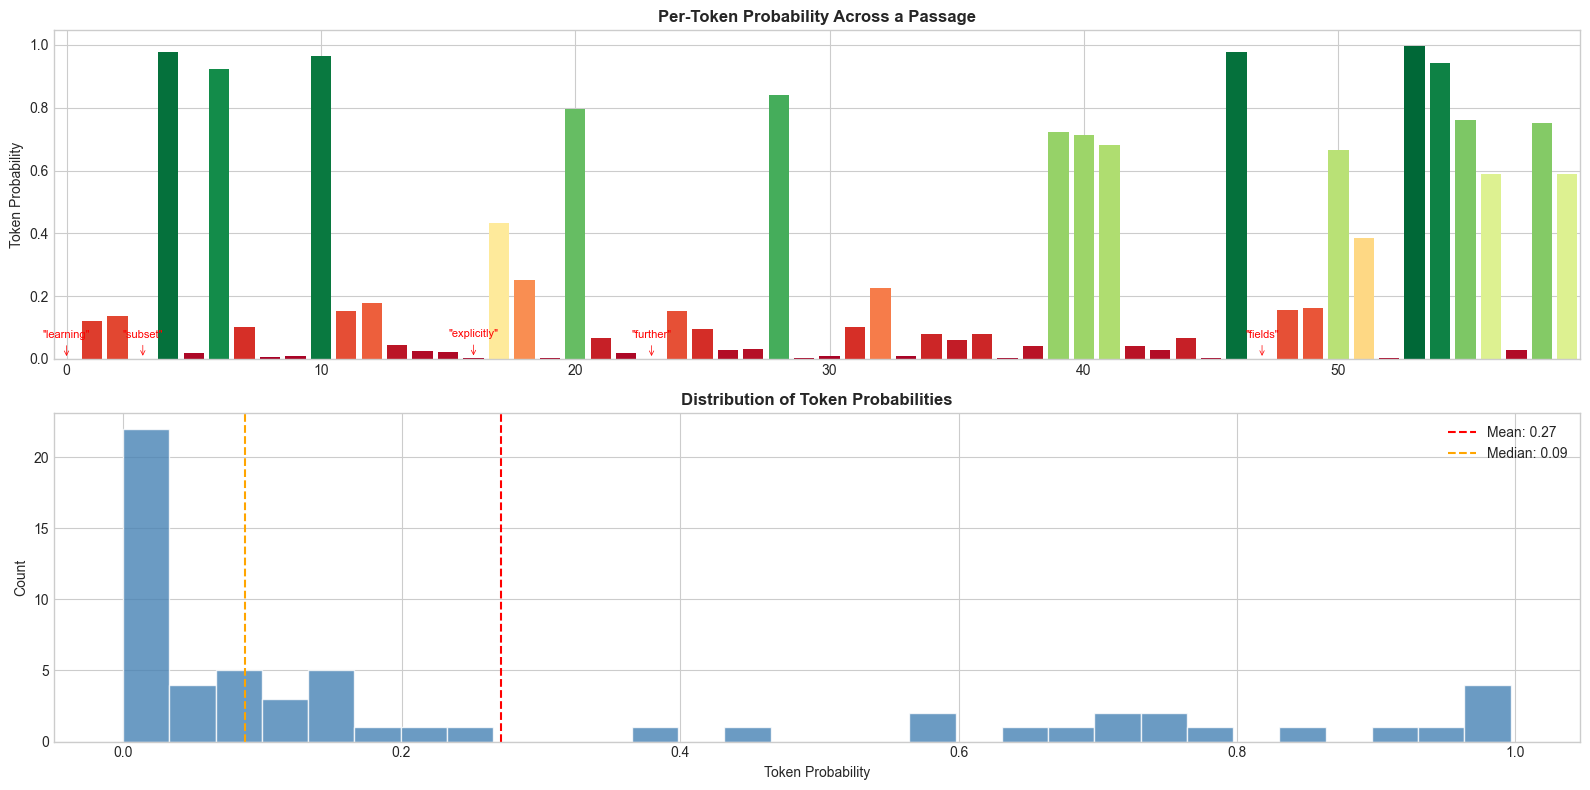

Total tokens: 60
Mean probability: 0.272
Median probability: 0.088
Min probability: 0.0001 (token: 'learning')
Max probability: 0.9965 (token: 'language')


In [6]:
text = (
    "Machine learning is a subset of artificial intelligence that enables "
    "computers to learn from data without being explicitly programmed. "
    "Deep learning, a further subset, uses neural networks with many layers "
    "to model complex patterns in large amounts of data. "
    "These techniques have revolutionized fields like computer vision, "
    "natural language processing, and speech recognition."
)

results = score_text(text)
probs = [r["prob"] for r in results]
tokens = [r["token"].strip() for r in results]

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Top: token-by-token probability
ax = axes[0]
colors = [plt.cm.RdYlGn(p) for p in probs]
bars = ax.bar(range(len(probs)), probs, color=colors, edgecolor="none")
ax.set_ylabel("Token Probability")
ax.set_title("Per-Token Probability Across a Passage", fontweight="bold")
ax.set_xlim(-0.5, len(probs) - 0.5)

# Label the 5 lowest-probability tokens
sorted_indices = np.argsort(probs)[:5]
for idx in sorted_indices:
    ax.annotate(f'"{tokens[idx]}"', xy=(idx, probs[idx]),
                xytext=(0, 15), textcoords="offset points",
                ha="center", fontsize=8, color="red",
                arrowprops=dict(arrowstyle="->", color="red", lw=0.5))

# Bottom: histogram of probabilities
ax = axes[1]
ax.hist(probs, bins=30, color="steelblue", edgecolor="white", alpha=0.8)
ax.axvline(np.mean(probs), color="red", linestyle="--", label=f"Mean: {np.mean(probs):.2f}")
ax.axvline(np.median(probs), color="orange", linestyle="--", label=f"Median: {np.median(probs):.2f}")
ax.set_xlabel("Token Probability")
ax.set_ylabel("Count")
ax.set_title("Distribution of Token Probabilities", fontweight="bold")
ax.legend()

plt.tight_layout()
plt.show()

print(f"Total tokens: {len(probs)}")
print(f"Mean probability: {np.mean(probs):.3f}")
print(f"Median probability: {np.median(probs):.3f}")
print(f"Min probability: {np.min(probs):.4f} (token: '{tokens[np.argmin(probs)]}')")
print(f"Max probability: {np.max(probs):.4f} (token: '{tokens[np.argmax(probs)]}')")

## Workshop Summary

### The Full Pipeline

```
Input Text
    ↓
Tokenizer (BPE)          → Token IDs [464, 3139, 286, ...]
    ↓
Transformer Model         → Logits (raw scores, one per vocab token)
    ↓
Temperature Scaling        → Logits / T  (reshape distribution)
    ↓
Softmax                   → Probabilities (sum to 1.0)
    ↓
Sampling (top-k/top-p)   → Selected token
    ↓
Append & Repeat           → Autoregressive loop
```

### Key Insights from This Workshop

1. **Logits → Softmax → Probabilities** is the core computation at every generation step
2. **Temperature** controls creativity vs. consistency — it's just division before softmax
3. **Top-p/top-k** prevent sampling garbage from the long tail of the distribution
4. **Perplexity** quantifies how natural text is to a model — lower = more expected
5. **Token probabilities reveal uncertainty** — low-prob tokens in factual contexts may signal hallucination
6. **Sequence probability** is the product of individual token probabilities (sum of log-probs)
7. **KV caching** makes autoregressive generation efficient by reusing past computations

### Practical Applications of Token Probabilities
- **Hallucination detection**: Flag low-confidence tokens in critical outputs
- **Model evaluation**: Compare models via perplexity on benchmark text
- **Output ranking**: Generate multiple candidates, pick the highest-confidence one (best-of-N)
- **Confidence calibration**: Build systems that know when to say "I'm not sure"
- **Watermarking**: Embed signals in the sampling process for AI-generated text detection